# TAD calling

This tutorial calls topologically associating domains (TADs) from
chromatin traces with `uchrom.strc.tad.call_tads_by_pval` (also
`uc.tl.call_tads`), U-Chrom's implementation of the ArcFISH TAD caller
(Yu et al. 2025, bioRxiv 10.1101/2025.11.26.690837): its p-value test with
the nested hierarchy, and its insulation-score method.  It gives the
authors' per-locus statistics and calls (`benchmarks/arcfish_parity`).  The
tutorial then runs the callers on a **backed** `.chromdata.zarr` store with
`streaming=True`, projects TADs and loops onto bins and spots with
`uchrom.strc.enrichment.add_structural_features`, and finally compares
imaging TADs with directionality-index TADs called on Hi-C of the same loci
(`uchrom.strc.tad.call_tads_di`, `compare_boundaries`).
Data, both as a `ChromData` from `ds.load`: Takei et al. 2021 (*Nature*
590:344) mESC DNA seqFISH+ at 25 kb (`"takei2021_mesc"`: the first call
downloads the FOF-CT core table `4DNFIHF3JCBY`, 22 MB, and its cell and RNA
tables once from 4DN; replicate 2, `4DNFIQXONUUH`, 34 MB, is fetched for
the comparison with the paper), and Su et al. 2020 (*Cell* 182:1641) IMR90
chr21, 651 loci of 50 kb, with the authors' Rao et al. 2014 Hi-C summed into
the same loci and linked as a cooler (`"su2020_chr21"`: the first call
downloads both tables once from Zenodo 3928890, 262 MB, and builds the
dataset in the data directory, ~10 s).  Runtime: about 10 minutes on 8 CPU
cores, most of it the ArcFISH call on the 7,591 Su 2020 traces.

**How the caller works** (per chromosome): after the same per-axis variance
normalisation as the loop caller, each locus `b` at least half a window from
both ends of the region is tested as a boundary.  The loci within the window
on its left and on its right form two candidate domains; if `b` is a
boundary, pairs *within* a side vary less than pairs *across* it.  A
per-axis F-test of within / across variance, combined over the axes with the
Cauchy test, gives one statistic per locus (`stat`); the boundaries are the
local maxima of its variant with F(1, 1) p-values (`stat_prox`) whose
Benjamini–Hochberg FDR over all tested loci is below `fdr_cutoff`.
**Level 0** of the result is the finest partition, the domains between
consecutive boundaries (the first and the last locus count as boundaries).
With `hierarchical=True` (the default) the boundaries are then removed one
at a time, weakest first, and each removal adds the merged domain at the
next level (1, 2, …): a tree of nested domains up to the whole region.

In [1]:
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from chromdata import ChromData
import uchrom as uc
import uchrom.datasets as ds

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)

## Load the Takei 2021 traces

In [2]:
cd = ds.load("takei2021_mesc")
cd

ChromData: n_spots=316995, n_traces=8285, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  cells:   ['extra_cell_roi_id', 'keep1', 'centroid_x', 'centroid_y', 'nucleus_area_um2', 'cytoplasm_area_um2', 'rna.Eef2', 'rna.Auts2', 'rna.Bdnf', 'rna.Clu', 'rna.Cx3cr1', 'rna.Efna5', 'rna.Npy', 'rna.S100b', 'rna.Slc17a7', 'rna.Stmn2', 'rna.Zfp42', 'rna.Myc', 'rna.Ccnd2', 'rna.Mcm2', 'rna.Mki67', 'rna.Sox2', 'rna.Nes', 'rna.Cdk1', 'rna.Mtf2', 'rna.Jade1', 'rna.Cenpa', 'rna.Aurka', 'rna.Plk1', 'rna.Mdm2', 'rna.Aebp2', 'rna.Tet1', 'rna.Nodal', 'rna.Tfcp2l1', 'rna.Tdh', 'rna.Sall4', 'rna.Nanog', 'rna.Esrrb', 'rna.Pou5f1', 'rna.Klf6', 'rna.Ctgf', 'rna.Peg10', 'rna.Myh9', 'rna.Tbx3', 'rna.Otx2', 'rna.Dnmt3a', 'rna.Dnmt3b', 'rna.Lin28a', 'rna.Lin28b', 'rna.Zscan4c', 'rna.Zfp352'] (201 cells)
  points:  {'rna': 3335}
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly', 'fofct_companions', 'cell_spatial', 'dataset']

## TADs on one chromosome

`window_bp` is the distance on **each** side of a locus: the loci within it
on the left and on the right form the two segments tested (ArcFISH's
`window`).  The default, `1e5` (±100 kb), is ArcFISH's; a smaller window is
compared below.

In [3]:
from uchrom.strc.tad import TADCallerParams, call_tads_by_pval

ARC = TADCallerParams(window_bp=1e5)          # ±100 kb, ArcFISH's default; fdr_cutoff=0.1, all levels
tads6 = call_tads_by_pval(cd, chrom="chr6", params=ARC, key_added="tads.chr6", verbose=True)
print(f"level 0: {(tads6.level == 0).sum()} TADs; levels 1-{tads6.level.max()}: one merged domain each")
tads6[tads6.level == 0]

[tad/chr6] variance cube...


[tad/chr6] axis weights: [0.339 0.3   0.361]


[tad/chr6] 5 boundaries (fdr < 0.1)
level 0: 6 TADs; levels 1-5: one merged domain each


,chrom,start,end,level,start1,end1,start2,end2,stat1,stat2
0,chr6,49375000,49500000,0,49375000,49400000,49500000,49525000,NaN,1.360018e+03
1,chr6,49500000,49925000,0,49500000,49525000,49925000,49950000,1.360018e+03,5.042245e+01
2,chr6,49925000,50075000,0,49925000,49950000,50075000,50100000,5.042245e+01,2.794177e+06
3,chr6,50075000,50300000,0,50075000,50100000,50300000,50325000,2.794177e+06,4.405725e+06
4,chr6,50300000,50625000,0,50300000,50325000,50625000,50650000,4.405725e+06,2.414535e+12
5,chr6,50625000,50900000,0,50625000,50650000,50900000,50925000,2.414535e+12,NaN


Each row is a domain: `start1, end1` and `start2, end2` are its left and
right boundary loci, `stat1` and `stat2` their statistics (NaN for the first
and the last locus of the region, which are not tested).  A domain runs from
the start of its left boundary locus to the start of its right one, so the
domains of a level tile the region and each boundary locus begins the next
domain.  The per-locus test behind the calls — the table of ArcFISH's
`TADCaller.by_pval` — is `arcfish_boundary_stats`; `peak` marks the
boundaries:

In [4]:
from uchrom.strc.tad.arc_pval import arcfish_boundary_stats

stats6 = arcfish_boundary_stats(cd, chrom="chr6", params=ARC)        # one row per locus; not stored
stats6.loc[stats6.peak, ["chrom", "start", "stat", "stat_prox", "pval", "fdr"]]

,chrom,start,stat,stat_prox,pval,fdr
4,chr6,49500000,1.360018e+03,0.083168,2.340482e-04,1.456300e-03
21,chr6,49925000,5.042245e+01,0.024340,6.312033e-03,2.945616e-02
27,chr6,50075000,2.794177e+06,0.096029,1.139190e-07,1.594866e-06
36,chr6,50300000,4.405725e+06,0.083534,7.224915e-08,1.348651e-06
48,chr6,50625000,2.414535e+12,0.167242,1.317835e-13,7.379874e-12


The domain table is stored as a `domain` interval table:

In [5]:
cd.intervals["tads.chr6"].kind, cd.results.record("tads.chr6").function

('domain', 'uchrom.strc.tad.call_tads_by_pval')

## TADs on the median distance map

A good call outlines the low-distance blocks along the diagonal of the
population median distance map.  Left: the finest partition (level 0);
right: every level — each merged domain contains the finer ones, up to the
whole region at the top.  `uchrom.pl.draw_domains` outlines a domain table
on any map whose rows are the loci in `dm.bins`.

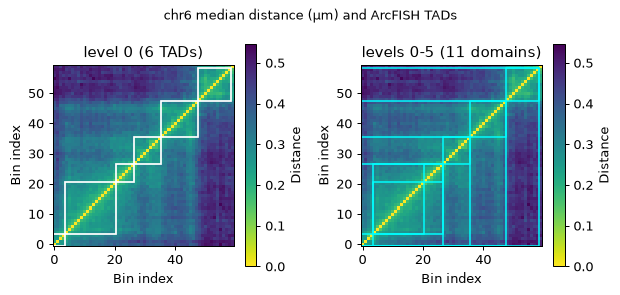

In [6]:
from uchrom.fea import distance_map
from uchrom.pl import draw_domains, plot_distance_matrix

dm = distance_map(cd, "chr6")
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
plot_distance_matrix(dm.matrix, title=f"level 0 ({(tads6.level == 0).sum()} TADs)", ax=axes[0])
draw_domains(axes[0], tads6, dm.bins, level=0, edgecolor="white", lw=1.4)
plot_distance_matrix(dm.matrix, title=f"levels 0-{tads6.level.max()} ({len(tads6)} domains)", ax=axes[1])
draw_domains(axes[1], tads6, dm.bins, edgecolor="cyan", lw=1.2)
fig.suptitle("chr6 median distance (µm) and ArcFISH TADs", fontsize=10)
plt.tight_layout(); plt.show()

## All chromosomes, the window and the insulation method

`chrom=None` (the default) calls every chromosome and merges the tables
under one key, `"tads.arcfish"`.  `tad_boundaries` places the boundaries of
a domain table (its finest level) on the loci of `cd` — the first locus of
a TAD or the first locus after it, leaving out the outer edges of each
region's TADs.  We count them for ArcFISH's window, for half of it, and for
ArcFISH's second method, `method="insulation"`: the normalised insulation
score of Su et al. 2020 on the median distances, whose peaks are the
boundaries (here peaks of prominence 0.04 at least 2 loci apart, the
settings of the ArcFISH paper on these data).

In [7]:
from uchrom.strc.tad import tad_boundaries

INSULATION = TADCallerParams(method="insulation", prominence=0.04, distance=2)   # window ±100 kb
tads = uc.tl.call_tads(cd, params=ARC)        # method="arcfish" -> call_tads_by_pval; stored as "tads.arcfish"
calls = {"p-value, window_bp=1e5 (±100 kb)": tads,
         "p-value, window_bp=5e4 (±50 kb)": uc.tl.call_tads(cd, params=TADCallerParams(window_bp=5e4),
                                                            key_added=None),
         "insulation, ±100 kb": uc.tl.call_tads(cd, params=INSULATION, key_added=None)}
summary = []
for name, table in calls.items():
    b = tad_boundaries(cd, table)                # level 0 of the hierarchy
    summary.append({"setting": name, "boundaries": len(b), "regions with a boundary": b.chrom.nunique(),
                    "level-0 TADs": int((table.level == 0).sum())})
pd.DataFrame(summary).set_index("setting")

,boundaries,regions with a boundary,level-0 TADs
setting,,,
"p-value, window_bp=1e5 (±100 kb)",85,20,105
"p-value, window_bp=5e4 (±50 kb)",27,13,47
"insulation, ±100 kb",140,20,160


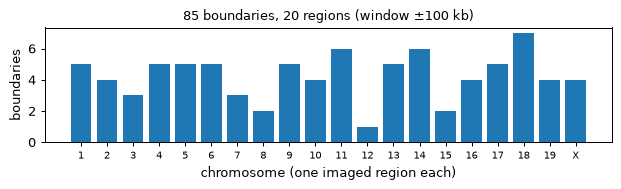

In [8]:
from uchrom.io import sort_chroms

b = tad_boundaries(cd, "tads.arcfish")
order = sort_chroms(cd.bins.chrom)                # chr1, chr2, ..., chr19, chrX
counts = b.groupby("chrom").size().reindex(order, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.bar(range(len(counts)), counts.to_numpy(), color="tab:blue")
ax.set_xticks(range(len(counts)), [c.replace("chr", "") for c in counts.index], fontsize=8)
ax.set_xlabel("chromosome (one imaged region each)"); ax.set_ylabel("boundaries")
ax.set_title(f"{len(b)} boundaries, {len(order)} regions (window ±100 kb)", fontsize=10)
plt.tight_layout(); plt.show()

**How this compares with the paper.**  The ArcFISH preprint reports 105 TAD
boundaries on this dataset (insulation score: 135), from both replicates of
the experiment.  The table above uses replicate 1: the test finds fewer
boundaries (85), the insulation score about as many (140).  Replicate 2 is
the 4DN FOF-CT core table `4DNFIQXONUUH` (`ds.fetch("takei_rep2")`); call
on both replicates together:

In [9]:
rep2 = ChromData.from_fofct(ds.fetch("takei_rep2"))   # replicate 2: the 4DN FOF-CT core table, fetched once

def loci_and_traces(c, rep):                           # trace ids made unique per replicate
    sp = c.spots_with_loci()[["chrom", "start", "end"]]
    return sp.assign(trace_id=rep + "_" + c.spots["trace_id"].astype(str).to_numpy())

both = ChromData(coords=np.vstack([np.asarray(cd.coords), np.asarray(rep2.coords)]),
                 spots=pd.concat([loci_and_traces(cd, "rep1"), loci_and_traces(rep2, "rep2")], ignore_index=True))
print(f"both replicates: {both.n_traces} traces")
print("boundaries:", {name: len(tad_boundaries(both, uc.tl.call_tads(both, params=p, key_added=None)))
                      for name, p in {"p-value": ARC, "insulation": INSULATION}.items()})

both replicates: 18383 traces


boundaries: {'p-value': 105, 'insulation': 135}


The paper's numbers: the caller gives the authors' calls
(`benchmarks/arcfish_parity` compares them locus by locus), and with the
traces of one replicate the test has less power.  Halving the window leaves
two loci on each side of a locus and far fewer boundaries (27 on
replicate 1, none in seven regions).

## Streaming on a backed store, and projecting structures onto bins

For data that do not fit in memory, open a `.chromdata.zarr` store
**backed**: only the small tables are loaded, coordinates stay on disk.
The dataset `ds.load` built is such a store, so `backed=True` is all it
takes.  (For your own FOF-CT tables, `ChromData.from_fofct(path, out=store)`
streams the table into a store chunk by chunk and returns it opened
backed.)

In [10]:
back = ds.load("takei2021_mesc", backed=True)
print(back)
print(f"working-memory budget of the streaming paths: {uc.settings.memory_budget / 1e9:.1f} GB")

ChromData (backed: takei2021_mesc.chromdata.zarr): n_spots=316995, n_traces=8285, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  cells:   ['extra_cell_roi_id', 'keep1', 'centroid_x', 'centroid_y', 'nucleus_area_um2', 'cytoplasm_area_um2', 'rna.Eef2', 'rna.Auts2', 'rna.Bdnf', 'rna.Clu', 'rna.Cx3cr1', 'rna.Efna5', 'rna.Npy', 'rna.S100b', 'rna.Slc17a7', 'rna.Stmn2', 'rna.Zfp42', 'rna.Myc', 'rna.Ccnd2', 'rna.Mcm2', 'rna.Mki67', 'rna.Sox2', 'rna.Nes', 'rna.Cdk1', 'rna.Mtf2', 'rna.Jade1', 'rna.Cenpa', 'rna.Aurka', 'rna.Plk1', 'rna.Mdm2', 'rna.Aebp2', 'rna.Tet1', 'rna.Nodal', 'rna.Tfcp2l1', 'rna.Tdh', 'rna.Sall4', 'rna.Nanog', 'rna.Esrrb', 'rna.Pou5f1', 'rna.Klf6', 'rna.Ctgf', 'rna.Peg10', 'rna.Myh9', 'rna.Tbx3', 'rna.Otx2', 'rna.Dnmt3a', 'rna.Dnmt3b', 'rna.Lin28a', 'rna.Lin28b', 'rna.Zscan4c', 'rna.Zfp352'] (201 cells)
  points:  {'rna': 3335}
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly', 'fofct_co

On a backed object the ArcFISH TAD and loop callers stream over the traces
of each chromosome (`streaming=True` is the default there; it is spelled
out here): the variance statistics are accumulated in trace batches with
memory `O(n_bins²)` instead of `O(n_traces × n_bins²)`, in float64.  The
calls equal the in-memory ones; the statistics differ only by rounding (the
in-memory call above runs in float32 if it uses Apple MPS).  The calls are
stored in the backed object's `intervals` / `results`, like in memory.

In [11]:
t0 = time.perf_counter()
tads_b = uc.tl.call_tads(back, params=ARC, streaming=True)
loops_b = uc.tl.call_loops(back, streaming=True)
print(f"streaming calls: {time.perf_counter() - t0:.1f} s; {len(tads_b)} TAD rows, {len(loops_b)} loops")

key = ["chrom", "start", "end", "level"]
same = tads_b[key].reset_index(drop=True).equals(tads[key].reset_index(drop=True))
rel = np.abs(tads_b.stat1.to_numpy() / tads.stat1.to_numpy() - 1)
print("same TADs as in memory:", same, "| max relative difference of the boundary statistics:", float(np.nanmax(rel)))
print(back.intervals)

streaming calls: 21.2 s; 190 TAD rows, 10 loops
same TADs as in memory: True | max relative difference of the boundary statistics: 3.76946251989807e-11
IntervalStore({'tads.arcfish': <domain, 190 rows>, 'loops.axiswise_f': <pair, 10 rows>})


`add_structural_features` turns the interval tables into per-locus
features in `bin_tracks` (prefix `strc.`): distance to the nearest TAD
boundary, whether the locus lies in a TAD, whether it overlaps a loop
anchor (and how many), and the distance to the nearest anchor.  It finds
the calls under their default keys (`"tads.arcfish"`, `"loops.axiswise_f"`,
`"compartments.axes_pc"` when present) and records the features in the
feature registry.

In [12]:
from uchrom.strc.enrichment import add_structural_features

features = add_structural_features(back)
print(list(back.bin_tracks.columns))
back.bins.join(back.bin_tracks).query("`strc.loop_anchor_overlap` == 1")

['strc.distance_to_tad_boundary', 'strc.inside_tad', 'strc.loop_anchor_overlap', 'strc.loop_anchor_count', 'strc.distance_to_loop_anchor']


,chrom,start,end,strc.distance_to_tad_boundary,strc.inside_tad,strc.loop_anchor_overlap,strc.loop_anchor_count,strc.distance_to_loop_anchor
bin_id,,,,,,,,
255,chr13,21900000,21925000,62500.0,1.0,1.0,1.0,0.0
259,chr13,22000000,22025000,12500.0,1.0,1.0,1.0,0.0
261,chr13,22050000,22075000,37500.0,1.0,1.0,1.0,0.0
264,chr13,22275000,22300000,262500.0,1.0,1.0,1.0,0.0
279,chr13,23275000,23300000,112500.0,1.0,1.0,1.0,0.0
280,chr13,23300000,23325000,87500.0,1.0,1.0,1.0,0.0
283,chr13,23375000,23400000,12500.0,1.0,1.0,1.0,0.0
284,chr13,23400000,23425000,12500.0,1.0,1.0,1.0,0.0
288,chr13,23500000,23525000,12500.0,1.0,1.0,1.0,0.0


Bin tracks follow every spot through its `bin_id`.  Reading one
chromosome from the store gives an in-memory object whose
`tracks_spot_view()` lines the features up with the spots:

In [13]:
chr2 = back.get_chrom("chr2")                    # reads one chromosome partition
spots = chr2.spots_with_loci().join(chr2.tracks_spot_view(["strc.loop_anchor_overlap",
                                                            "strc.distance_to_tad_boundary"]))
spots.groupby("strc.loop_anchor_overlap").size().rename("spots").to_frame().T

strc.loop_anchor_overlap,0.0,1.0
spots,13319,533


`score_loops` checks the loops against the traces themselves: for each
loop, the 3-D distance of its two anchors in every trace that detected
both, against the distances of the other locus pairs of the chromosome at
the same genomic separation.  It reads one chromosome of the backed store
at a time.

In [14]:
from uchrom.strc.loop import score_loops

scores = score_loops(back)                       # the loops stored under "loops.axiswise_f"
scores[["chrom1", "start1", "start2", "n_traces", "anchor_distance", "background_distance", "ratio"]].round(3)

,chrom1,start1,start2,n_traces,anchor_distance,background_distance,ratio
0,chr13,21900000,22000000,195,0.215,0.290,0.741
1,chr13,22050000,22275000,176,0.290,0.398,0.729
2,chr13,23275000,23375000,229,0.216,0.290,0.746
3,chr13,23300000,23500000,209,0.304,0.382,0.796
4,chr13,23400000,23500000,227,0.228,0.290,0.786
5,chr16,91075000,91350000,210,0.235,0.353,0.667
6,chr2,109900000,110200000,171,0.218,0.349,0.625
7,chr6,50300000,50525000,174,0.195,0.298,0.657
8,chr6,50675000,50800000,131,0.170,0.264,0.642
9,chrX,76825457,76925457,114,0.189,0.274,0.691


The structures live in the backed object's small tables.  `write` saves
everything to a new store (a backed object loads its data for that, so
this is meant for stores that fit in memory; the original store is not
changed):

In [15]:
saved = OUT / "takei2021_25kb_structures.chromdata.zarr"
if saved.exists():
    shutil.rmtree(saved)
back.write(saved)
again = ChromData.read(saved, backed=True)
print(again.intervals)
print("results:", list(again.results))
print("bin tracks:", list(again.bin_tracks.columns))

IntervalStore({'tads.arcfish': <domain, 190 rows>, 'loops.axiswise_f': <pair, 10 rows>})
results: ['tads.arcfish', 'loops.axiswise_f', 'bin_features']
bin tracks: ['strc.distance_to_tad_boundary', 'strc.inside_tad', 'strc.loop_anchor_overlap', 'strc.loop_anchor_count', 'strc.distance_to_loop_anchor']


## Imaging TADs vs Hi-C TADs on the same loci (Su et al. 2020)

Su et al. 2020 traced the q-arm of chr21 (651 loci of 50 kb, 7,591
chromosome copies in IMR90 cells) and summed Rao et al. 2014 IMR90 Hi-C
reads into the same loci.  That allows a direct comparison: ArcFISH TADs on
the imaging, and Dixon et al. 2012 directionality-index (DI) TADs on the
Hi-C with `call_tads_di`.  `ds.load("su2020_chr21")` gives one trace per
imaged chromosome copy (loci not detected in a copy are left out,
coordinates in µm), the number of genes the authors list per locus in
`bin_tracks["n_genes"]`, and the Hi-C as a linked cooler.  The loader
reads the authors' tables with `uchrom.io.read_su2020_tracing` and
`read_su2020_hic` and writes the Hi-C with `uchrom.io.write_locus_cool`;
the same readers take the other tables of the record (chromosome 2, the
genome-scale DNA-MERFISH data).

In [16]:
su = ds.load("su2020_chr21")
print(su)
print(f"{su.n_traces} chromosome copies, {su.n_bins} loci, "
      f"{1 - su.n_spots / (su.n_traces * su.n_bins):.1%} of the locus positions not detected")
su.uns["linked_cool"]

ChromData: n_spots=4622909, n_traces=7591, n_bins=651
  spots:   ['chrom', 'start', 'end', 'trace_id', 'bin_id']
  tracks (bins):  ['n_genes']
  uns:     ['genome_assembly', 'xyz_unit', 'source', 'linked_cool', 'dataset']
7591 chromosome copies, 651 loci, 6.5% of the locus positions not detected


{'rao2014': {'path': 'su2020_chr21_rao2014.cool',
  'format': 'cool',
  'label': 'Rao 2014 IMR90 Hi-C summed into the Su 2020 loci',
  'genome_assembly': 'hg38'}}

In [17]:
t0 = time.perf_counter()
tads_su = uc.tl.call_tads(su, params=TADCallerParams(window_bp=1e5, hierarchical=False))   # ±100 kb, ArcFISH's default
b_img = tad_boundaries(su, tads_su)
print(f"ArcFISH on imaging: {len(tads_su)} TADs, {len(b_img)} boundaries ({time.perf_counter() - t0:.0f} s)")

ArcFISH on imaging: 93 TADs, 92 boundaries (475 s)


`call_tads_di` reads the contact matrix of a `.cool` file linked to the
`ChromData` — here the key `"rao2014"` that the loader linked (the file
stays next to the store; `write_locus_cool` lets the cooler bins tile the
chromosome, so each bin runs from one imaged locus to the next, after an
empty leading bin).  The
`DICallerParams` defaults (a 50-bin window, smoothing over 10 % and a
minimum TAD of 5 % of the bins) suit a whole chromosome at 40 kb; for
these 651 loci we use a 10-locus window (≈0.5 Mb), 1 % smoothing and a
0.5 % minimum size.

In [18]:
from uchrom.strc.tad import DICallerParams

DI = DICallerParams(window=10, smoothing_param=0.01, min_size_frac=0.005)
di = uc.tl.call_tads(su, method="di", contacts="rao2014", params=DI)
print(f"DI on Hi-C: {len(di)} domains, {len(tad_boundaries(su, di))} boundaries")
print(su.intervals)

DI on Hi-C: 44 domains, 43 boundaries
IntervalStore({'tads.arcfish': <domain, 93 rows>, 'tads.di': <domain, 44 rows>})


How often does a Hi-C (DI) boundary fall within one locus of an imaging
(ArcFISH) boundary, compared with what random positions would give?
`compare_boundaries` answers it on the loci of `su`.  The same question for
a coarser DI call (20-locus window, more smoothing) shows how much the
answer depends on the DI settings.

In [19]:
from uchrom.strc.tad import compare_boundaries

coarse = uc.tl.call_tads(su, method="di", contacts="rao2014", key_added=None,
                         params=DICallerParams(window=20, smoothing_param=0.02, min_size_frac=0.01))
for name, table in (("DI, 10-locus window", di), ("DI, 20-locus window", coarse)):
    c = compare_boundaries(su, table, tads_su, tol=1)
    print(f"{name}: {c['fraction_near']:.0%} of {c['n_query']} boundaries within one locus of an ArcFISH boundary "
          f"(random positions: {c['chance']:.0%})")

DI, 10-locus window: 63% of 43 boundaries within one locus of an ArcFISH boundary (random positions: 41%)
DI, 20-locus window: 46% of 28 boundaries within one locus of an ArcFISH boundary (random positions: 41%)


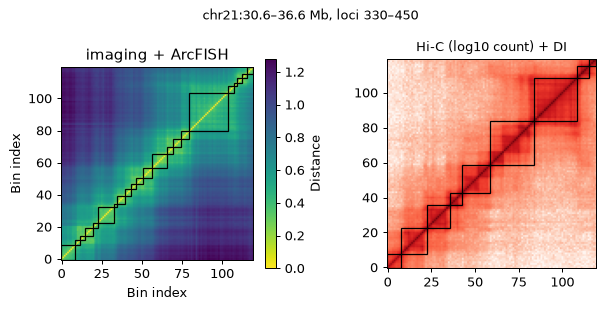

In [20]:
lo, hi = 330, 450                                             # a stretch of chr21q: loci 330-449
loci = su.bins.sort_values("start")
region = ("chr21", int(loci.start.iat[lo]), int(loci.start.iat[hi]))
window = ((su.spots["start"] >= region[1]) & (su.spots["start"] < region[2])).to_numpy()
dm_su = distance_map(su[window], "chr21")
clr = su.load_linked_cool("rao2014")                          # the linked Hi-C (cooler.Cooler): a bin per locus
H, hic_bins = clr.matrix(balance=False).fetch(region), clr.bins().fetch(region)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.3))
plot_distance_matrix(dm_su.matrix, title="imaging + ArcFISH", ax=axes[0])
axes[1].imshow(np.log10(H + 1), cmap="Reds", origin="lower")
axes[1].set_title("Hi-C (log10 count) + DI", fontsize=10)
draw_domains(axes[0], tads_su, dm_su.bins, edgecolor="k", lw=1)
draw_domains(axes[1], di, hic_bins, edgecolor="k", lw=1)
fig.suptitle(f"chr21:{region[1] / 1e6:.1f}–{region[2] / 1e6:.1f} Mb, loci {lo}–{hi}", fontsize=10)
plt.tight_layout(); plt.show()

**How this compares with the paper.**  On these data the ArcFISH preprint
reports 49 boundaries (insulation score: 53) with a window of ±300 kb
(`figures/2tad_benchmark.ipynb` of the authors' repository).  With those
settings this caller gives 48 boundaries (`TADCallerParams(window_bp=3e5)`)
and 53 (`method="insulation", prominence=0.025, distance=5`); they are not
run here, the p-value call takes about 9 minutes.  ArcFISH's default window,
used above, gives a finer partition (92 boundaries).  The Hi-C boundaries of
the DI caller fall near imaging boundaries more often than random positions
would, but far from one to one, and the agreement depends strongly on the
DI window and smoothing: with the coarser setting it is close to chance.

## Notes

- `call_tads_by_pval`, `call_loops_axiswise_f` and
  `call_compartments_axes_pc` share the variance normalisation of
  `uchrom.fea.arc`; its exact medians over the traces take most of the run
  time on large populations (about 9 minutes for the 7,591 Su 2020 traces
  on 8 CPU cores).
- For a flat partition use `hierarchical=False` (or `level == 0`); the
  per-locus statistics are `arcfish_boundary_stats`.
- `uc.tl.call_tads(cd, method=...)` dispatches to `"arcfish"` / `"pval"`
  (this caller; ArcFISH's insulation method is
  `TADCallerParams(method="insulation")`), `"fishnet"` (single-allele
  domains) and, on linked Hi-C maps, `"insulation"` and `"di"`.
- The deprecated helpers `uchrom.strc.call_structures_multi` /
  `call_tads_multi` / … still work (with a `DeprecationWarning`); the
  callers with `chrom=None` replace them.

## Next steps

- `fishnet_domains` — domains on single alleles, compared with these
  population boundaries.
- `loop_calling` — loops on the same data.
- `compartment` — A/B compartments on Su 2020 chr21, validated against the
  same Hi-C.